# Baltimore Marriage Certificates — TrOCR (HuggingFace)

An alternative OCR engine to compare against Docling/RapidOCR.

**Key fact:** TrOCR is a *line-level* recognizer — it transcribes a single line of text, not a whole page. So this notebook uses a **detection + recognition** hybrid:

1. Render a processed PDF page to an image
2. **RapidOCR** detects text-line bounding boxes (detection only)
3. Crop each line and feed it to **TrOCR** for recognition
4. Reassemble lines top-to-bottom into page text

Model: `microsoft/trocr-base-printed` (swap to `-handwritten` for cursive fields). First run downloads ~330 MB from HuggingFace.

In [10]:
from pathlib import Path

import numpy as np
import pypdfium2 as pdfium
import torch
from PIL import Image
from rapidocr import RapidOCR
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data/baltimore-marriage-certificates/processed"

# --- config ---
PDF_NAME = "1_content.pdf"   # processed PDF (auto-detected certificate pages)
PAGE_INDEX = 0                 # 0-based page index within that PDF
RENDER_SCALE = 2.0            # higher = sharper crops, slower
TROCR_MODEL = "microsoft/trocr-base-printed"  # or "microsoft/trocr-base-handwritten"
REC_BATCH_SIZE = 8

PDF_PATH = PROCESSED_DIR / PDF_NAME
print(f"PDF exists: {PDF_PATH.exists()}  ({PDF_PATH})")

PDF exists: True  (/Users/akhileshmadyastha/Desktop/projects/document-understanding/data/baltimore-marriage-certificates/processed/1_content.pdf)


Rendered page size: (1224, 1584)


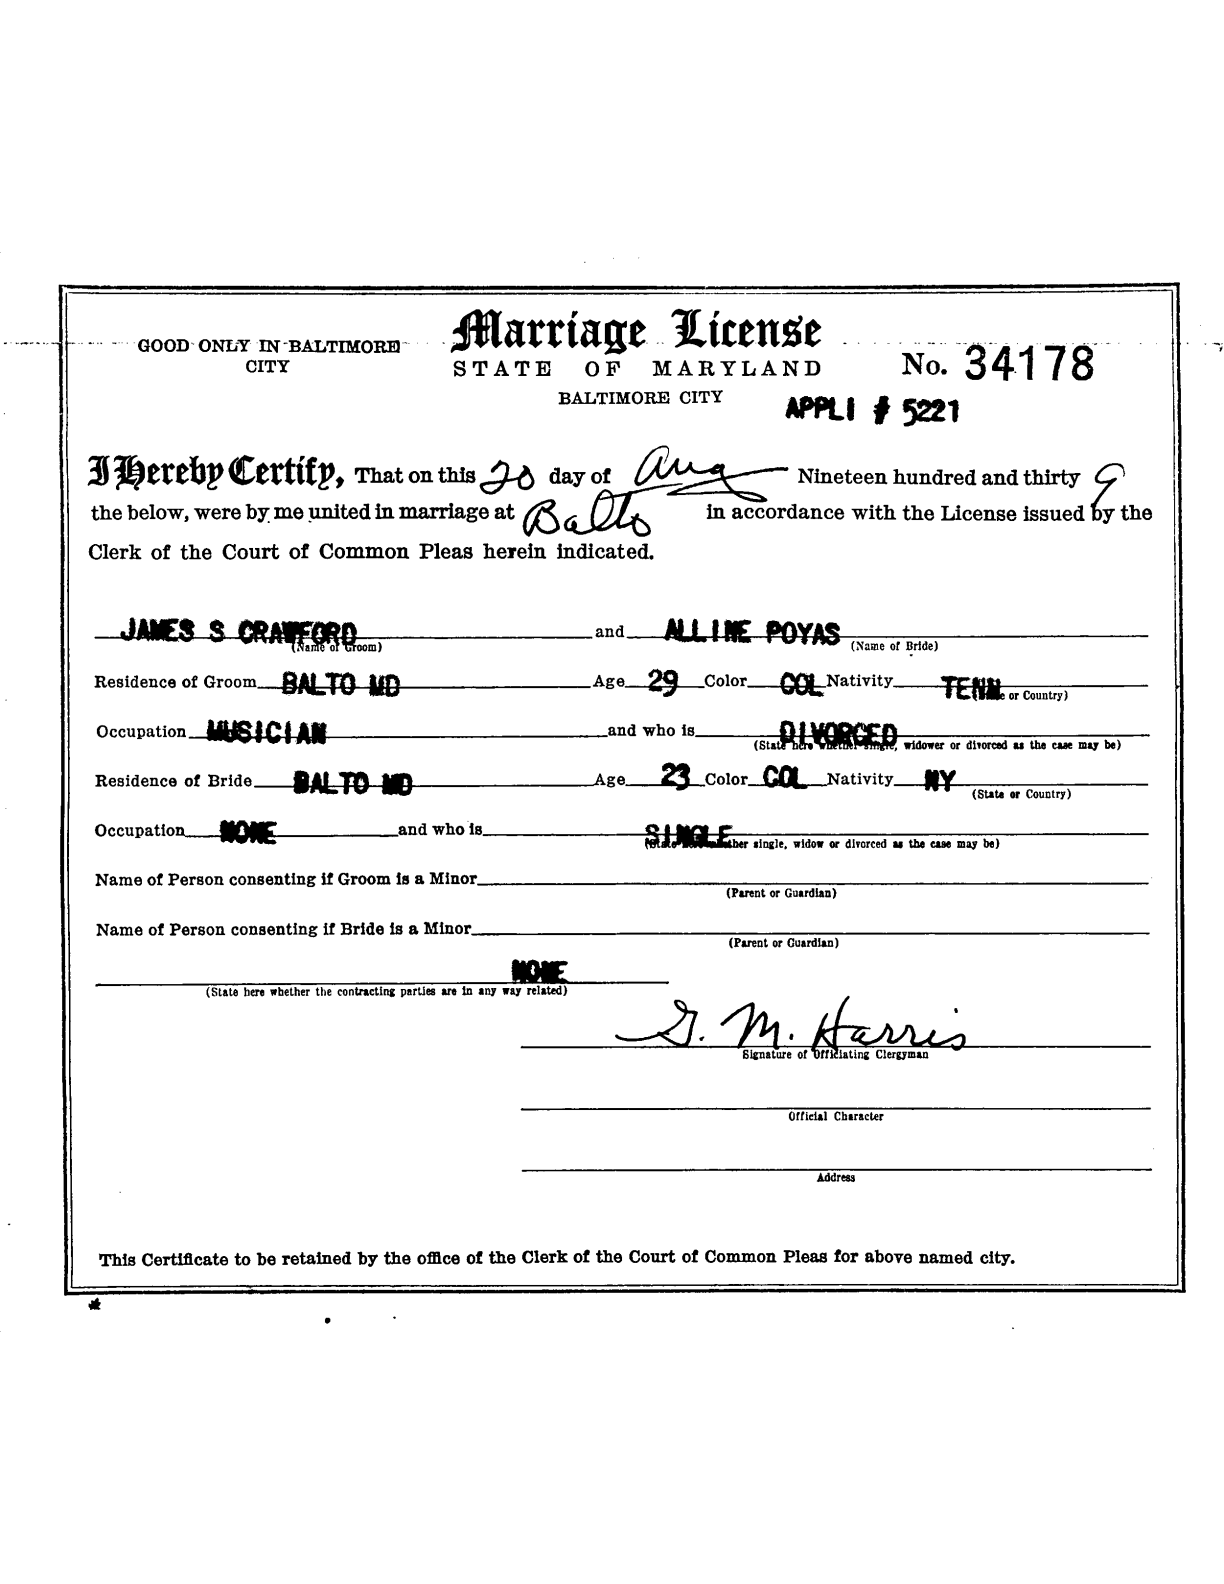

In [11]:
# 1. Render one PDF page to a PIL image
def render_page(pdf_path: Path, page_index: int, scale: float) -> Image.Image:
    pdf = pdfium.PdfDocument(str(pdf_path))
    page = pdf[page_index]
    pil = page.render(scale=scale).to_pil().convert("RGB")
    pdf.close()
    return pil


page_image = render_page(PDF_PATH, PAGE_INDEX, RENDER_SCALE)
print(f"Rendered page size: {page_image.size}")
page_image

In [12]:
# 2. Detection only: RapidOCR gives text-line bounding boxes (no recognition)

detector = RapidOCR()

det_result = detector(
    np.array(page_image),
    use_det=True,
    use_cls=False,
    use_rec=False,
)
boxes = det_result.boxes if det_result.boxes is not None else []
print(f"Detected {len(boxes)} text lines")

[INFO] 2026-07-03 12:28:09,479 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-07-03 12:28:09,490 [RapidOCR] download_file.py:60: File exists and is valid: /Users/akhileshmadyastha/Desktop/projects/document-understanding/.venv/lib/python3.11/site-packages/rapidocr/models/PP-OCRv6_det_small.onnx
[INFO] 2026-07-03 12:28:09,491 [RapidOCR] main.py:63: Using /Users/akhileshmadyastha/Desktop/projects/document-understanding/.venv/lib/python3.11/site-packages/rapidocr/models/PP-OCRv6_det_small.onnx
[INFO] 2026-07-03 12:28:09,524 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-07-03 12:28:09,527 [RapidOCR] download_file.py:60: File exists and is valid: /Users/akhileshmadyastha/Desktop/projects/document-understanding/.venv/lib/python3.11/site-packages/rapidocr/models/ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-07-03 12:28:09,527 [RapidOCR] main.py:63: Using /Users/akhileshmadyastha/Desktop/projects/document-understanding/.venv/lib/python3.11/site-packages

Detected 42 text lines


In [6]:
# Order boxes top-to-bottom, then left-to-right, and crop each line
def box_bounds(quad):
    xs = [float(p[0]) for p in quad]
    ys = [float(p[1]) for p in quad]
    return int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))


def order_boxes(boxes, row_tol: int = 15):
    bounds = [box_bounds(b) for b in boxes]
    # sort by y first, then group rows that are within row_tol, then sort each row by x
    order = sorted(range(len(bounds)), key=lambda i: (bounds[i][1], bounds[i][0]))
    rows, current, last_y = [], [], None
    for i in order:
        y0 = bounds[i][1]
        if last_y is None or abs(y0 - last_y) <= row_tol:
            current.append(i)
        else:
            rows.append(current)
            current = [i]
        last_y = y0
    if current:
        rows.append(current)
    ordered = []
    for row in rows:
        ordered.extend(sorted(row, key=lambda i: bounds[i][0]))
    return [bounds[i] for i in ordered]


ordered_bounds = order_boxes(boxes)
line_crops = [page_image.crop((x0, y0, x1, y1)) for (x0, y0, x1, y1) in ordered_bounds]
print(f"Prepared {len(line_crops)} line crops")

Prepared 42 line crops


In [7]:
# 3. Load TrOCR (processor + vision-encoder-decoder model)
device = "cuda" if torch.cuda.is_available() else "cpu"

processor = TrOCRProcessor.from_pretrained(TROCR_MODEL)
model = VisionEncoderDecoderModel.from_pretrained(TROCR_MODEL).to(device)
model.eval()
print(f"Loaded {TROCR_MODEL} on {device}")

Loading weights: 100%|██████████| 478/478 [00:00<00:00, 10131.37it/s]
[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded microsoft/trocr-base-printed on cpu


In [8]:
# 4. Recognize all line crops (batched) and reassemble page text
@torch.no_grad()
def recognize(crops, batch_size: int) -> list[str]:
    texts: list[str] = []
    for start in range(0, len(crops), batch_size):
        batch = crops[start : start + batch_size]
        pixel_values = processor(images=batch, return_tensors="pt").pixel_values.to(device)
        generated = model.generate(pixel_values, max_new_tokens=64)
        texts.extend(processor.batch_decode(generated, skip_special_tokens=True))
    return texts


line_texts = recognize(line_crops, REC_BATCH_SIZE)
page_text = "\n".join(t for t in line_texts if t.strip())

print(page_text)

AMARTIAGE LICENSE
GOOD ONLY IN BALTIMORE
NO. 34178
CITY
STATE
OF MARYLAND
BALTIMORE CITY
APPLI # 5221
3-BEREDY CERTIER, TAXTON THIS 20 DAY OF ALLA
NINETEEN HUNDRED AND THIRTY
THE BELOW, WERE BY THE UNITED IN MARNAGE AT (BACOT)
IN ACCORDANCE WITH THE LICENSE ISSUED BY THE
CLERK OF THE COUNT OF COMMUN PLEAS HEREIN INDICATED.
JAMES S CRAWFORD.
AND ALLINE POYAS
(NAME OF GROOM)
(NAME OF BRIDE)
RESIDENCE OF GROOM BALTO MD
AGE 29 COLOR COL NATIVITY TENN.
E OR COUNTRY)
OCCUPATION MUSICIAN
AND WHO IS_
(STATE BOO CASH
PLYORDED
WIDOWER OR DIVORCED AS THE CAKE MAY BE)
RESIDENCE OF BRIDE_
BALTO MO
AGE 23 COLOR COL NATIVITY NY
(STATE OR COUNTRY)
OCCUPATION_
AND WHO IS.
NAME OF PERSON CONSENTING IF GROOM IS A MINOR.
(PARENT OR GUARDIAN)
NAME OF PERSON CONSENTING IF BRIDE IS A MINOR.
(PARENT OR GUARDIAN)
(STATE HERE WHERE THE CONTRACING DRTLES ARE IN ANY WAY RELATED)
AM.KAWIS
SIGNATURE OF OFFICATING CERYMAN
OFFICIAL CHARACTER
ADDRESS
THIS CREDICATE TO BE RETAINED BY THE COMICE OF THE CLACK OF THE CONT

In [9]:
# Process every processed PDF, all pages, with the detection + TrOCR pipeline.
# Resumable: each page is appended to a JSONL checkpoint as soon as it finishes,
# so if the kernel dies you can just re-run this cell and it continues where it
# stopped (already-transcribed pages are skipped).
import json

CHECKPOINT_PATH = PROJECT_ROOT / "data/baltimore-marriage-certificates/trocr_checkpoint.jsonl"
CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)


def load_checkpoint(path: Path) -> dict[str, dict[int, str]]:
    """Rebuild {pdf_name: {page_number: text}} from an existing checkpoint."""
    done: dict[str, dict[int, str]] = {}
    if not path.exists():
        return done
    with path.open() as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            rec = json.loads(line)
            done.setdefault(rec["source_pdf"], {})[rec["page_number"]] = rec["text"]
    return done


def ocr_page(pil_image) -> str:
    det = detector(np.array(pil_image), use_det=True, use_cls=False, use_rec=False)
    page_boxes = det.boxes if det.boxes is not None else []
    if len(page_boxes) == 0:
        return ""
    bounds = order_boxes(page_boxes)
    crops = [pil_image.crop(b) for b in bounds]
    return "\n".join(t for t in recognize(crops, REC_BATCH_SIZE) if t.strip())


def ocr_pdf(pdf_path: Path, done_pages: dict[int, str], sink) -> dict[int, str]:
    pdf = pdfium.PdfDocument(str(pdf_path))
    n_pages = len(pdf)
    pdf.close()

    pages: dict[int, str] = dict(done_pages)  # start from what's already saved
    for page_index in range(n_pages):
        page_number = page_index + 1
        if page_number in pages:
            continue  # already transcribed in a previous run

        image = render_page(pdf_path, page_index, RENDER_SCALE)
        text = ocr_page(image)
        pages[page_number] = text

        # Append + flush immediately so progress survives a kernel crash.
        sink.write(json.dumps({
            "source_pdf": pdf_path.name,
            "page_number": page_number,
            "text": text,
        }) + "\n")
        sink.flush()

        print(f"  {pdf_path.name} page {page_number}/{n_pages} done")
    return pages


all_text = load_checkpoint(CHECKPOINT_PATH)
already = sum(len(p) for p in all_text.values())
if already:
    print(f"Resuming from checkpoint: {already} pages already transcribed\n")

# Open in append mode so a resumed run keeps prior lines.
with CHECKPOINT_PATH.open("a") as sink:
    for pdf_path in sorted(PROCESSED_DIR.glob("*_content.pdf")):
        print(f"Processing {pdf_path.name} ...")
        all_text[pdf_path.name] = ocr_pdf(
            pdf_path, all_text.get(pdf_path.name, {}), sink
        )

total_pages = sum(len(p) for p in all_text.values())
print(f"\nDone: {len(all_text)} PDFs, {total_pages} pages transcribed")
print(f"Checkpoint: {CHECKPOINT_PATH}")

Processing 1_odd_pages.pdf ...
  1_odd_pages.pdf page 1/131 done


KeyboardInterrupt: 

In [ ]:
# Save transcriptions to JSONL: one record per page
import json

OUTPUT_PATH = PROJECT_ROOT / "data/baltimore-marriage-certificates/trocr_output.jsonl"
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

with OUTPUT_PATH.open("w") as f:
    for pdf_name, pages in all_text.items():
        for page_number, text in pages.items():
            record = {
                "source_pdf": pdf_name,
                "page": page_number,
                "engine": TROCR_MODEL,
                "text": text,
            }
            f.write(json.dumps(record) + "\n")

print(f"Saved {sum(len(p) for p in all_text.values())} records to {OUTPUT_PATH}")